# Air Temperature compression: GPU-trained PyTorch MLP → CPU inference → residuals → ANS

A fixed 8→5→1 float64 ReLU MLP is trained on CUDA with PyTorch. Immediately after fitting the model is moved to CPU; all prediction, formula parity, validation codec evaluation, and timing are CPU-only. The chronological test partition remains reserved. This is a proof of concept, not an optimized deployment model.


## 1. Load and check the observed series

We preserve file order rather than sorting timestamps: duplicates and the recorded backward step are properties of this observed sequence. The original decimal strings are retained so the source grid can be inferred from training text only. This section loads libraries and verifies the expected source file.


In [1]:
import copy, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
_repo_candidates=[Path.cwd(),Path.cwd().parent,*[Path(entry) for entry in sys.path if entry]]
root=next((candidate.resolve() for candidate in _repo_candidates if (candidate/'compression_evaluation').is_dir()),None)
if root is None: raise RuntimeError('Could not locate repository compression_evaluation package')
sys.path.insert(0,str(root))
from compression_evaluation.poc import (chronological_bounds, impute_training_only, infer_decimal_quantum, make_windows, checked_ticks, snap_to_grid, fit_training_alphabet, evaluate_suffix, benchmark_pairs, make_codec_pair, pinned_allowed_cpu)
from compression_evaluation.poc_plots import plot_training_series, plot_training_distribution
np.random.seed(42); torch.manual_seed(42)
if not torch.cuda.is_available(): raise RuntimeError('CUDA is required for MLP training; CPU fallback is prohibited')
print('PyTorch:',torch.__version__,'CUDA:',torch.version.cuda,'GPU:',torch.cuda.get_device_name(0))


PyTorch: 2.9.0+cu126 CUDA: 12.6 GPU: NVIDIA GeForce GTX 1050 Ti


### Read the source and verify recorded chronology

Row counts, timestamp irregularities, and the missing value are checked explicitly. No temporal repair or reordering is performed.


In [2]:
csv=root/'datasets/AriviyalN_Data_Air_Temperature.csv'
a=pd.read_csv(csv,dtype={'Air Temperature':'string'})
a['Timestamp']=pd.to_datetime(a['Timestamp'],dayfirst=True,errors='coerce')
assert len(a)==51354 and a.Timestamp.notna().all()
backwards=int((a.Timestamp.diff()<pd.Timedelta(0)).sum()); duplicates=int(a.Timestamp.duplicated().sum())
assert (backwards,duplicates)==(1,192)
text=a['Air Temperature'].reset_index(drop=True)
values=pd.to_numeric(text,errors='coerce').to_numpy(dtype=np.float64)
n=len(values); train_end,val_end=chronological_bounds(n)
assert (train_end,val_end)==(35947,46218)
missing=np.flatnonzero(np.isnan(values)); assert missing.tolist()==[34567]
values=impute_training_only(values,train_end,val_end)
step=float(infer_decimal_quantum(text.iloc[:train_end])); assert step==.1
train,valid=values[:train_end],values[train_end:val_end]
print(f'Rows={n}; duplicates={duplicates}; backwards={backwards}; split={train_end}/{val_end}/{n}; step={step}; reserved test rows={n-val_end}')


Rows=51354; duplicates=192; backwards=1; split=35947/46218/51354; step=0.1; reserved test rows=5136


## 2. Split chronologically and inspect training data

The fixed positional 70/20/10 split separates earliest training, later validation, and final reserved test observations. Only training-side missing data may be imputed. One-step windows stay inside their partition, so no context crosses a boundary.


### Form within-partition windows and inspect plots

Training pairs are shuffled once with the fixed seed for fitting; this does not change chronological boundaries or the sequence plots. The validation contexts remain in their original order.


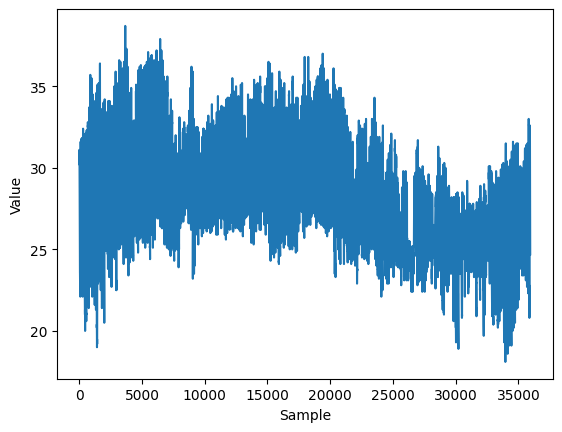

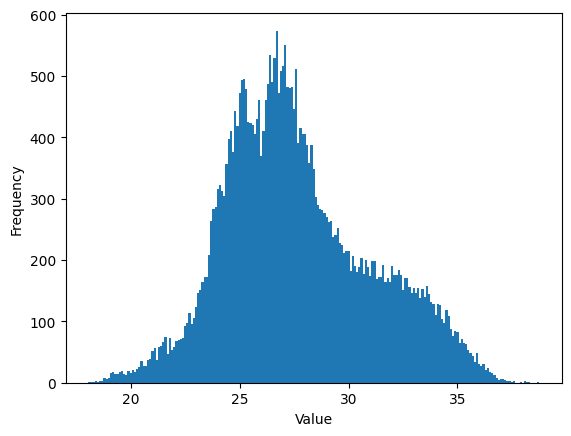

Training windows: (35939, 8) validation: (10263, 8) training pairs shuffled once with seed 42


In [3]:
X_train_ordered,y_train_ordered=make_windows(train); X_valid,y_valid=make_windows(valid)
order=np.random.default_rng(42).permutation(len(X_train_ordered)); X_train,y_train=X_train_ordered[order],y_train_ordered[order]
fig=plot_training_series(train); plt.show()
fig=plot_training_distribution(train,step); plt.show()
print('Training windows:',X_train.shape,'validation:',X_valid.shape,'training pairs shuffled once with seed 42')


### Verify split counts

The validation study starts with eight observed values as bootstrap context; only subsequent values are coded.


In [4]:
assert len(train)==35947 and len(valid)==10271 and n-val_end==5136
assert X_train.shape==(35939,8) and X_valid.shape==(10263,8)
print('Train rows/windows:',len(train),len(X_train),'validation rows/windows:',len(valid),len(X_valid),'reserved test rows:',n-val_end)


Train rows/windows: 35947 35939 validation rows/windows: 10271 10263 reserved test rows: 5136


## 3. Train on GPU, then report raw CPU prediction quality

The unchanged fixed model is trained in CUDA using float64, Adam, learning rate 0.01, 50 epochs, and batches of 16. Validation loss is monitoring only. Immediately after fitting, inference moves to a frozen CPU copy. Raw prediction MAE/MSE measure next-value prediction; persistence repeats the last context value as a simple baseline. The quality gate requires both validation errors to improve.


### Fit the fixed 8→5→1 ReLU model

Training settings and optimizer behavior are kept intact. The CUDA synchronization makes the fit duration meaningful; all later calls use CPU.


In [5]:
torch.set_default_dtype(torch.float64)
model=nn.Sequential(nn.Linear(8,5),nn.ReLU(),nn.Linear(5,1)).double().cuda()
X_train_t=torch.from_numpy(X_train).to('cuda'); y_train_t=torch.from_numpy(y_train.reshape(-1,1)).to('cuda')
X_valid_t=torch.from_numpy(X_valid).to('cuda'); y_valid_t=torch.from_numpy(y_valid.reshape(-1,1)).to('cuda')
optimizer=torch.optim.Adam(model.parameters(),lr=.01); criterion=nn.MSELoss()
initial=[p.detach().clone() for p in model.parameters()]
fit_start=time.perf_counter()
for epoch in range(50):
    for start in range(0,len(X_train_t),16):
        xb=X_train_t[start:start+16]; yb=y_train_t[start:start+16]
        optimizer.zero_grad(set_to_none=True); loss=criterion(model(xb),yb)
        if not torch.isfinite(loss): raise FloatingPointError(f'nonfinite loss at epoch {epoch}')
        loss.backward()
        if any(p.grad is None or not torch.isfinite(p.grad).all() for p in model.parameters()): raise FloatingPointError(f'nonfinite/missing gradient at epoch {epoch}')
        optimizer.step()
    with torch.no_grad(): val_loss=criterion(model(X_valid_t),y_valid_t)
    if not torch.isfinite(val_loss): raise FloatingPointError(f'nonfinite validation loss at epoch {epoch}')
torch.cuda.synchronize(); fit_seconds=time.perf_counter()-fit_start
assert any(not torch.equal(p.detach(),old) for p,old in zip(model.parameters(),initial)), 'training did not change parameters'
# Immediate post-fit transition: never forward on CUDA after this point.
cpu_model=copy.deepcopy(model).to('cpu').eval()
for p in cpu_model.parameters(): p.requires_grad_(False)
del model,optimizer,criterion,X_train_t,y_train_t,X_valid_t,y_valid_t
assert all(p.device.type=='cpu' for p in cpu_model.parameters()) and all(b.device.type=='cpu' for b in cpu_model.buffers())
print('Fit seconds (CUDA synchronized):',fit_seconds,'epochs=50; batch=16; optimizer=Adam(.01); post-fit model=CPU')


Fit seconds (CUDA synchronized): 160.55498654600524 epochs=50; batch=16; optimizer=Adam(.01); post-fit model=CPU


### Define CPU PyTorch inference

The predictor accepts finite float64 matrices with eight columns and makes no GPU forward calls.


In [6]:
def _validated_input(X):
    X=np.asarray(X,dtype=np.float64)
    if X.ndim!=2 or X.shape[1]!=8 or X.shape[0]<1 or not np.isfinite(X).all(): raise ValueError('input must be finite float64 with shape (n, 8)')
    return X

def torch_predict(X):
    X=_validated_input(X); t=torch.from_numpy(X)
    assert t.device.type=='cpu'
    with torch.no_grad(): out=cpu_model(t)
    result=out.numpy().astype(np.float64,copy=True)
    assert out.device.type=='cpu' and result.shape==(len(X),1) and np.isfinite(result).all()
    return result


### Compute raw metrics and persistence comparison

These metrics are unsnapped model errors and must not be confused with decoded reconstruction error. A failing quality gate is reported, not hidden.


In [7]:
def report_metrics(pred,y):
    e=np.asarray(y).reshape(-1)-np.asarray(pred).reshape(-1)
    return {'MAE':float(np.mean(np.abs(e))),'MSE':float(np.mean(e**2))}
Xtr,ytr=make_windows(train)
train_pred=torch_predict(Xtr); valid_pred=torch_predict(X_valid)
train_base=Xtr[:,-1,None]; valid_base=X_valid[:,-1,None]
print('Train PyTorch:',report_metrics(train_pred,ytr),'persistence:',report_metrics(train_base,ytr))
print('Validation PyTorch:',report_metrics(valid_pred,y_valid),'persistence:',report_metrics(valid_base,y_valid))

mlp_valid_metrics = report_metrics(valid_pred, y_valid)
persistence_valid_metrics = report_metrics(valid_base, y_valid)
mlp_quality_pass = all(mlp_valid_metrics[key] < persistence_valid_metrics[key] for key in ('MAE', 'MSE'))
print('MLP validation quality vs persistence:', 'PASS' if mlp_quality_pass else 'FAIL', '(both MAE and MSE must improve)')


Train PyTorch: {'MAE': 2.7017194151997743, 'MSE': 11.38167244690455} persistence: {'MAE': 0.21553465594479534, 'MSE': 0.11484821503102478}
Validation PyTorch: {'MAE': 2.504338483574839, 'MSE': 9.046433865264017} persistence: {'MAE': 0.21583357692682456, 'MSE': 0.12135925168079509}
MLP validation quality vs persistence: FAIL (both MAE and MSE must improve)


## 4. Inspect signed training residuals

Residual coding compares each target tick with the predictor output snapped to the training-inferred 0.1 grid. The signed residual is target minus snapped prediction: positive means above prediction, negative means below. This is a codec diagnostic, not the raw predictor error.


### Derive training-only signed ticks and view their distribution

No validation values influence the residual alphabet. The histogram reports signed physical residuals; the half-tick check illustrates why snapping and its rounding boundary matter.


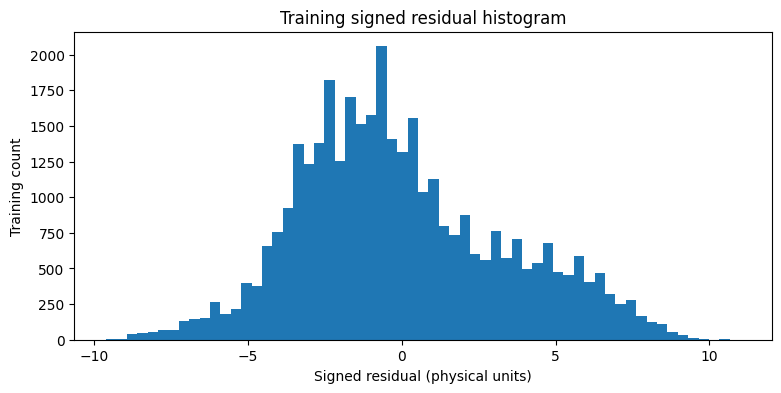

Signed residual ticks: 35939 min/max: -96 110 ; snap boundary check passed


In [8]:
train_target_ticks=checked_ticks(ytr,step,'training targets')
train_prediction_ticks=checked_ticks(snap_to_grid(train_pred,step),step,'snapped training predictions')
train_residual_ticks=train_target_ticks-train_prediction_ticks
train_signed_residuals=train_residual_ticks.astype(np.float64)*step
assert len(train_signed_residuals)==len(ytr) and np.isfinite(train_signed_residuals).all()
plt.figure(figsize=(9,4)); plt.hist(train_signed_residuals,bins=61); plt.xlabel('Signed residual (physical units)'); plt.ylabel('Training count'); plt.title('Training signed residual histogram'); plt.show()
half=step/2; left=np.array([[half-np.spacing(half)*4]]); right=np.array([[half+np.spacing(half)*4]])
assert np.allclose(left,right,rtol=1e-10,atol=1e-10) and int(np.rint(left[0,0]/step)) != int(np.rint(right[0,0]/step))
print('Signed residual ticks:',len(train_residual_ticks),'min/max:',int(train_residual_ticks.min()),int(train_residual_ticks.max()),'; snap boundary check passed')


## 5. Fit the training alphabet and check quantization / ANS

Only training targets and CPU PyTorch training predictions fit the padded signed residual support and normalized frequency table. Validation residuals may fall outside this support and must then fail explicitly rather than silently expand the alphabet. ANS symbols are zero-based indices derived from signed ticks.


### Build and inspect the fixed training-fitted frequency table

The model and table are shared read-only study state and are not transmitted in the measured payload. Frequencies are positive integers summing to 1024.


In [9]:
alphabet=fit_training_alphabet(ytr,train_pred,step,pad_ticks=5,total_frequency=1024)
print('Training alphabet ticks:',alphabet.low_tick,'..',alphabet.high_tick,'levels:',len(alphabet.frequencies),'frequency sum:',sum(alphabet.frequencies))
assert len(alphabet.frequencies)>0 and all(f>0 for f in alphabet.frequencies) and sum(alphabet.frequencies)==1024


Training alphabet ticks: -101 .. 115 levels: 217 frequency sum: 1024


### Quantizer support and symbol checks

The signed grid is preserved while the coder indexes the finite table. Off-grid and out-of-support symbols are rejected by the established quantizer/coder path.


In [10]:
from compression_evaluation.poc import SignedGridQuantizer
quantizer=SignedGridQuantizer(step,alphabet.low_tick,alphabet.high_tick)
assert quantizer.levels==len(alphabet.frequencies)
for symbol in range(quantizer.levels): assert quantizer.value_to_symbol(quantizer.symbol_to_value(symbol))==symbol
print('Quantizer boundary and supported-symbol roundtrip checks passed')


Quantizer boundary and supported-symbol roundtrip checks passed


## 6. Assemble independent codec pairs and bootstrap

Each encoder/decoder pair begins with its own copy of the same eight observed validation values. Those eight values are bootstrap state, not coded symbols. The table and model are shared study state; the measured payload excludes these metadata costs.


### Verify the bootstrap and independent histories

Factories create fresh pairs so previous encodes cannot affect later runs. Encoder and decoder prediction histories are separate and initialized identically.


In [11]:
validation_bootstrap=np.asarray(valid[:8],dtype=np.float64).copy()
validation_suffix=np.asarray(valid[8:],dtype=np.float64)
assert validation_bootstrap.shape==(8,) and len(validation_suffix)==10263

def validation_pair_factory(predictor):
    return make_codec_pair(validation_bootstrap,predictor,alphabet,step)


## 7. Evaluate numeric full-validation codec once

This single numeric study uses all 10,271 validation values: eight initialize rolling history and 10,263 suffix values are coded. Evaluator reconstruction metrics describe fidelity after coding, distinct from raw MAE/MSE. Entropy is a source statistic; actual finite-stream payload rate includes coder overhead.


### Run the CPU PyTorch full-validation study

This evaluator call is the one primary numeric pass. It is not the controlled paired CPU timing benchmark reported later.


In [12]:
ks=evaluate_suffix(valid,torch_predict,alphabet,step)
print('Numeric full validation:',ks.metrics,'payload bytes:',ks.metrics.get('compressed_size_bytes'),'ratio:',ks.metrics.get('compression_ratio'),'entropy bits/symbol:',ks.entropy_bits,'bits/symbol:',ks.metrics.get('bits_per_symbol'),'bootstrap bytes/ratio:',ks.bootstrap_bytes,ks.bootstrap_ratio)
assert len(ks.symbols)==10263 and ks.bootstrap_bytes==ks.metrics['compressed_size_bytes']+64


Numeric full validation: {'encode_time_sec': 2.727938071002427, 'encode_mem_mb': 1144.59765625, 'decode_time_sec': 2.105414960999042, 'decode_mem_mb': 1144.421875, 'compression_ratio': 9.109508487739932, 'bits_per_symbol': 7.025626035272338, 'mse': 1.1303393674186993e-29, 'snr_db': 318.4865982870498, 'uncompressed_size_bytes': 82104, 'compressed_size_bytes': 9013, 'symbol_count': 10263} payload bytes: 9013 ratio: 9.109508487739932 entropy bits/symbol: 6.815577033201794 bits/symbol: 7.025626035272338 bootstrap bytes/ratio: 9077 9.052330064999449


## 8. Export same-weights NumPy formula and verify parity

The formula is a direct NumPy implementation of the frozen CPU model: affine layer, ReLU, affine output, using the exact same copied weights. Formula parity checks are implementation equivalence, not predictive quality. The alphabet was already fit from training-only CPU predictions.


### Export immutable parameters and implement formula

Parameter shapes and immutable snapshots guard against accidental edits to the exported formula.


In [13]:
W0=cpu_model[0].weight.detach().numpy().T.copy(); b0=cpu_model[0].bias.detach().numpy().copy()
W1=cpu_model[2].weight.detach().numpy().T.copy(); b1=cpu_model[2].bias.detach().numpy().copy()
assert [W0.shape,b0.shape,W1.shape,b1.shape]==[(8,5),(5,),(5,1),(1,)]
for w in (W0,b0,W1,b1): w.setflags(write=False)
_export_snapshot=tuple(w.copy() for w in (W0,b0,W1,b1))
def numpy_predict(X):
    X=_validated_input(X); result=np.maximum(X@W0+b0,0)@W1+b1
    assert result.shape==(len(X),1) and np.isfinite(result).all()
    return result


### Check formula parity on training and full validation contexts

Raw outputs are compared with strict tolerance and snapped ticks must match exactly. This checks every validation context before the second codec study.


In [14]:
all_X=np.concatenate([Xtr,X_valid]); assert all_X.shape==(46202,8)
ta=torch_predict(all_X); na=numpy_predict(all_X)
raw_diff=float(np.max(np.abs(ta-na)))
assert np.allclose(ta,na,rtol=1e-10,atol=1e-10),f'raw parity failed: max abs diff={raw_diff}'
assert np.array_equal(checked_ticks(snap_to_grid(ta,step),step),checked_ticks(snap_to_grid(na,step),step))
probe=np.random.default_rng(42).choice(len(Xtr),size=256,replace=False)
assert np.allclose(torch_predict(Xtr[probe]),numpy_predict(Xtr[probe]),rtol=1e-10,atol=1e-10)
half=step/2; left=np.array([[half-np.spacing(half)*4]]); right=np.array([[half+np.spacing(half)*4]])
assert np.allclose(left,right,rtol=1e-10,atol=1e-10)
assert int(np.rint(left[0,0]/step)) != int(np.rint(right[0,0]/step)), 'synthetic half-tick must cross rounding boundary'
assert all(np.array_equal(w,s) for w,s in zip((W0,b0,W1,b1),_export_snapshot))
print('Parity passed: max abs diff',raw_diff,'rows',len(all_X),'including 256-row probe; half-tick sensitivity passed')


Parity passed: max abs diff 0.0 rows 46202 including 256-row probe; half-tick sensitivity passed


### Evaluate NumPy full validation once and prove byte parity

The second and only NumPy validation study must have identical symbols, payload bytes, and exact source-grid reconstruction to the CPU PyTorch study. A mismatch stops execution before timing.


In [15]:
ns=evaluate_suffix(valid,numpy_predict,alphabet,step)
assert np.array_equal(ks.symbols,ns.symbols)
# Fresh, independent pairs encode the full validation suffix; evaluate_suffix reports
# lengths/metrics, so explicitly verify the actual payload bytes and both roundtrips.
kenc,kdec=validation_pair_factory(torch_predict)
nenc,ndec=validation_pair_factory(numpy_predict)
ks_payload=kenc.encode(valid[8:]); ns_payload=nenc.encode(valid[8:])
assert isinstance(ks_payload,bytes) and isinstance(ns_payload,bytes)
assert ks_payload == ns_payload, 'byte-for-byte payload parity failed; do not report speedup'
if len(ks_payload)!=ks.metrics['compressed_size_bytes'] or len(ns_payload)!=ns.metrics['compressed_size_bytes']:
    print('Payload length mismatch:',len(ks_payload),ks.metrics['compressed_size_bytes'],len(ns_payload),ns.metrics['compressed_size_bytes'])
    raise AssertionError('actual payload lengths differ from primary-study metrics')
ks_decoded=kdec.decode(ks_payload); ns_decoded=ndec.decode(ns_payload)
source_ticks=checked_ticks(valid[8:],step)
assert np.array_equal(checked_ticks(ks_decoded,step),source_ticks)
assert np.array_equal(checked_ticks(ns_decoded,step),source_ticks)
for enc,dec in ((kenc,kdec),(nenc,ndec)):
    assert enc.predictor is not dec.predictor
    assert enc.predictor._window is not dec.predictor._window
    assert np.array_equal(enc.predictor._window,dec.predictor._window)
assert kenc.predictor is not nenc.predictor and kdec.predictor is not ndec.predictor
print('Byte-for-byte payload equality: PASS; PyTorch bytes:',len(ks_payload),'NumPy bytes:',len(ns_payload))
print('Alphabet:',alphabet.low_tick,'..',alphabet.high_tick,'levels',len(alphabet.frequencies),'frequency total',sum(alphabet.frequencies))
print('Independent codec histories and exact source-grid roundtrips passed')



Byte-for-byte payload equality: PASS; PyTorch bytes: 9013 NumPy bytes: 9013
Alphabet: -101 .. 115 levels 217 frequency total 1024
Independent codec histories and exact source-grid roundtrips passed


## 9. Compare controlled CPU codec timing

Fresh codec pairs run in NSSNNS order with the unchanged warmup and deadline. Both implementations use CPU inference. Report encode and decode medians and IQRs only when the complete paired benchmark succeeds; one-off evaluator profiling is not controlled timing.


### Run paired benchmark

The benchmark does not claim exclusive CPU isolation. Both models, alphabet, bootstrap, suffix, and codec behavior remain fixed.


In [16]:
def factory(predictor): return lambda: make_codec_pair(valid[:8],predictor,alphabet,step)
old_threads=torch.get_num_threads()
try:
    torch.set_num_threads(1)
    with pinned_allowed_cpu() as pinned_cpu, threadpool_limits(limits=1):
        bench=benchmark_pairs({'N':factory(torch_predict),'S':factory(numpy_predict)},valid[8:],step,order='NSSNNS',warmup_count=256,deadline_seconds=1500.)
finally: torch.set_num_threads(old_threads)
print('Pinned allowed CPU:',pinned_cpu,'complete:',bench.complete,'reason:',bench.reason)
if bench.complete:
    for run in bench.runs: print('run label:', 'CPU PyTorch codec' if run.kind=='N' else 'NumPy formula',run,'encode values/s:',len(valid[8:])/run.encode_s,'decode values/s:',len(valid[8:])/run.decode_s)
    print('NumPy formula vs CPU PyTorch codec median encode elapsed speedup (N/S):',bench.encode_speedup,'medians:',bench.encode_medians,'IQR:',bench.encode_iqr)
    print('NumPy formula vs CPU PyTorch codec median decode elapsed speedup (N/S):',bench.decode_speedup,'medians:',bench.decode_medians,'IQR:',bench.decode_iqr)
else: print('Incomplete benchmark; no speedup result reported')


Pinned allowed CPU: 0 complete: True reason: None
run label: CPU PyTorch codec TimedRun(kind='N', encode_s=2.731035867, decode_s=2.006936785, payload_bytes=9013) encode values/s: 3757.914761944794 decode values/s: 5113.763461164523
run label: NumPy formula TimedRun(kind='S', encode_s=1.640834421, decode_s=1.20104128, payload_bytes=9013) encode values/s: 6254.744457241002 decode values/s: 8545.0851447837
run label: NumPy formula TimedRun(kind='S', encode_s=1.663936528, decode_s=1.178965766, payload_bytes=9013) encode values/s: 6167.903539166729 decode values/s: 8705.087370620056
run label: CPU PyTorch codec TimedRun(kind='N', encode_s=2.416435767, decode_s=1.962563215, payload_bytes=9013) encode values/s: 4247.164414695572 decode values/s: 5229.3856939533025
run label: CPU PyTorch codec TimedRun(kind='N', encode_s=2.498861653, decode_s=1.966006376, payload_bytes=9013) encode values/s: 4107.0701083746635 decode values/s: 5220.227220666959
run label: NumPy formula TimedRun(kind='S', encod

## 10. Final-test status

No final-test evaluation is performed. The final chronological 10% remains reserved; validation results are not presented as test performance.


## 11. Interpretation and limitations

A successful formula parity result means two implementations of the same fitted weights agree; it does not cure poor validation prediction quality. Residual reconstruction error and raw next-value prediction error answer different questions. Payload compression ratio and bits per coded symbol exclude the bootstrap, model, frequency table, quantizer, and framing. The training-derived alphabet is fixed before validation, so unsupported validation residuals are an important limitation rather than an invitation to refit on validation.


## 12. Final results at a glance

Two rows compare CPU PyTorch with the exact same-weights NumPy ReLU formula. Raw validation MAE/MSE and reconstruction MSE are distinct. Payload ratio and entropy bits/symbol are shown alongside the 10,263 coded symbols. The bootstrap-inclusive estimate adds 64 bytes for eight float64 values, but still excludes model/table/quantizer/framing. Both rows include timing when complete; speedups are attached only to the exported formula row. The persistence baseline and quality gate remain visible. Test remains reserved.


In [17]:
# Confirm actual byte length and primary study metric agree; report all four values on defect.
_payload_values=(len(ks_payload),ks.metrics['compressed_size_bytes'],len(ns_payload),ns.metrics['compressed_size_bytes'])
if _payload_values[0]!=_payload_values[1] or _payload_values[2]!=_payload_values[3]:
    print('Payload bytes: len(PyTorch), metric(PyTorch), len(NumPy), metric(NumPy) =',*_payload_values)
    raise AssertionError('payload byte length does not match full-validation metrics')
assert ks_payload==ns_payload and len(ks.symbols)==len(ns.symbols)==10263
_raw_numpy=report_metrics(numpy_predict(X_valid),y_valid)
assert ks.bootstrap_bytes==len(ks_payload)+64 and ns.bootstrap_bytes==len(ns_payload)+64
assert ks.entropy_bits>0 and ns.entropy_bits>0
_rows=[]
for _name,_study,_raw,_kind in [('CPU PyTorch',ks,mlp_valid_metrics,'N'),('Exported NumPy ReLU formula',ns,_raw_numpy,'S')]:
    _row={'Predictor':_name,'Raw val MAE':_raw['MAE'],'Raw val MSE':_raw['MSE'],
      'Payload bytes':len(ks_payload) if _kind=='N' else len(ns_payload),
      'Payload ratio':_study.metrics['compression_ratio'],'Payload bits/symbol':_study.metrics['bits_per_symbol'],'Entropy bits/symbol':_study.entropy_bits,
      'Coded symbols':len(_study.symbols),'Reconstruction MSE':_study.metrics['mse'],
      'Bootstrap bytes':_study.bootstrap_bytes,'Bootstrap-inclusive ratio':_study.bootstrap_ratio,
      'Encode median (s)':np.nan,'Encode IQR (s)':np.nan,'Decode median (s)':np.nan,'Decode IQR (s)':np.nan,
      'Encode speedup (N/S)':np.nan,'Decode speedup (N/S)':np.nan}
    if bench.complete:
      _row.update({'Encode median (s)':bench.encode_medians[_kind],'Encode IQR (s)':bench.encode_iqr[_kind],
        'Decode median (s)':bench.decode_medians[_kind],'Decode IQR (s)':bench.decode_iqr[_kind]})
      if _kind=='S': _row.update({'Encode speedup (N/S)':bench.encode_speedup,'Decode speedup (N/S)':bench.decode_speedup})
    _rows.append(_row)
display(pd.DataFrame(_rows))
display(pd.DataFrame([{'Persistence validation MAE':persistence_valid_metrics['MAE'],
 'Persistence validation MSE':persistence_valid_metrics['MSE'],'MLP quality gate':'PASS' if mlp_quality_pass else 'FAIL'}]))
print('Same-weight formula equality checked; payload excludes bootstrap/model/table/quantizer/framing. Bootstrap-inclusive estimate adds 64 bytes. Final test reserved.')


,Predictor,Raw val MAE,Raw val MSE,Payload bytes,Payload ratio,Payload bits/symbol,Entropy bits/symbol,Coded symbols,Reconstruction MSE,Bootstrap bytes,Bootstrap-inclusive ratio,Encode median (s),Encode IQR (s),Decode median (s),Decode IQR (s),Encode speedup (N/S),Decode speedup (N/S)
0,CPU PyTorch,2.504338,9.046434,9013,9.109508,7.025626,6.815577,10263,1.130339e-29,9077,9.05233,2.498862,0.157300,1.966006,0.022187,NaN,NaN
1,Exported NumPy ReLU formula,2.504338,9.046434,9013,9.109508,7.025626,6.815577,10263,1.130339e-29,9077,9.05233,1.640834,0.061391,1.193410,0.011038,1.522921,1.647386


,Persistence validation MAE,Persistence validation MSE,MLP quality gate
0,0.215834,0.121359,FAIL


Same-weight formula equality checked; payload excludes bootstrap/model/table/quantizer/framing. Bootstrap-inclusive estimate adds 64 bytes. Final test reserved.
